# Air Quality UCI: Predicting CO Concentration

Regression analysis of the **Air Quality UCI** dataset: hourly readings from a gas multisensor device deployed in an Italian city, together with reference-analyzer concentrations and weather data.

**Goal:** predict the true hourly averaged CO concentration (`CO(GT)`, mg/m³) from the other sensor, weather and time features, and compare several regression models.

**Contents**
1. Setup
2. Data loading
3. Data wrangling and cleaning
4. Exploratory data analysis
5. Train/test split
6. Model training and comparison
7. Conclusions

## Dataset overview

Raw file: **9,357 rows × 15 columns** (`Date`, `Time` and 13 measurements).

| Column | Description |
|---|---|
| `CO(GT)` | True hourly averaged CO concentration, mg/m³ (**target**) |
| `PT08.S1(CO)` | Sensor 1 (tin oxide) response, related to CO |
| `NMHC(GT)` | True hourly averaged non-methane hydrocarbons, µg/m³ |
| `C6H6(GT)` | True hourly averaged benzene, µg/m³ |
| `PT08.S2(NMHC)` | Sensor 2 (titania) response, related to NMHC |
| `NOx(GT)` | True hourly averaged nitrogen oxides, ppb |
| `PT08.S3(NOx)` | Sensor 3 (tungsten oxide) response, related to NOx |
| `NO2(GT)` | True hourly averaged NO₂, µg/m³ |
| `PT08.S4(NO2)` | Sensor 4 (tungsten oxide) response, related to NO₂ |
| `PT08.S5(O3)` | Sensor 5 (indium oxide) response, related to O₃ |
| `T` | Temperature, °C |
| `RH` | Relative humidity, % |
| `AH` | Absolute humidity |

`Date` and `Time` are converted into the features `Year`, `Month`, `Day` and `Hour` during wrangling.

**Requirements:** `pandas`, `numpy`, `matplotlib`, `seaborn`, `scikit-learn`, `openpyxl`, and optionally `xgboost` (`pip install xgboost`).

## 1. Setup

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor

try:
    from xgboost import XGBRegressor
except ImportError:
    XGBRegressor = None
    print("xgboost is not installed (pip install xgboost); it will be skipped.")

# Configuration
DATA_PATH = "AirQualityUCI.xlsx"
TARGET = "CO(GT)"
RANDOM_STATE = 42
TEST_SIZE = 0.2
MISSING_VALUE = -200        # sentinel the UCI dataset uses for "no measurement"
MAX_MISSING_FRACTION = 0.5  # columns missing more often than this are dropped

sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", category=FutureWarning)

## 2. Data loading

In [2]:
df_raw = pd.read_excel('AirQualityUCI.xlsx', sheet_name='AirQualityUCI')
df_raw.head()

,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,2004-03-10,18:00:00,2.6,1360.00,150,11.881723,1045.50,166.0,1056.25,113.0,1692.00,1267.50,13.60,48.875001,0.757754
1,2004-03-10,19:00:00,2.0,1292.25,112,9.397165,954.75,103.0,1173.75,92.0,1558.75,972.25,13.30,47.700000,0.725487
2,2004-03-10,20:00:00,2.2,1402.00,88,8.997817,939.25,131.0,1140.00,114.0,1554.50,1074.00,11.90,53.975000,0.750239
3,2004-03-10,21:00:00,2.2,1375.50,80,9.228796,948.25,172.0,1092.00,122.0,1583.75,1203.25,11.00,60.000000,0.786713
4,2004-03-10,22:00:00,1.6,1272.25,51,6.518224,835.50,131.0,1205.00,116.0,1490.00,1110.00,11.15,59.575001,0.788794


## 3. Data wrangling and cleaning

### 3.1 Initial inspection

In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 9357 entries, 0 to 9356
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Date           9357 non-null   datetime64[us]
 1   Time           9357 non-null   object        
 2   CO(GT)         9357 non-null   float64       
 3   PT08.S1(CO)    9357 non-null   float64       
 4   NMHC(GT)       9357 non-null   int64         
 5   C6H6(GT)       9357 non-null   float64       
 6   PT08.S2(NMHC)  9357 non-null   float64       
 7   NOx(GT)        9357 non-null   float64       
 8   PT08.S3(NOx)   9357 non-null   float64       
 9   NO2(GT)        9357 non-null   float64       
 10  PT08.S4(NO2)   9357 non-null   float64       
 11  PT08.S5(O3)    9357 non-null   float64       
 12  T              9357 non-null   float64       
 13  RH             9357 non-null   float64       
 14  AH             9357 non-null   float64       
dtypes: datetime64[us](1), float64(12

In [4]:
print("Null values per column (pandas NaN):")
print(df_raw.isnull().sum().to_string())
print("\nDuplicate rows:", df_raw.duplicated().sum())

Null values per column (pandas NaN):
Date             0
Time             0
CO(GT)           0
PT08.S1(CO)      0
NMHC(GT)         0
C6H6(GT)         0
PT08.S2(NMHC)    0
NOx(GT)          0
PT08.S3(NOx)     0
NO2(GT)          0
PT08.S4(NO2)     0
PT08.S5(O3)      0
T                0
RH               0
AH               0

Duplicate rows: 0


### 3.2 Missing values

`isnull()` reports no missing values, but that is misleading: the UCI dataset encodes missing measurements as **-200**, which pandas reads as an ordinary number. Left in place, these values distort the correlations, the plots and the model fits (the scaler and every model treat -200 as a real reading). They are converted to `NaN` here and handled explicitly.

In [5]:
df = df_raw.copy()

numeric_cols = df.select_dtypes("number").columns
missing_summary = pd.DataFrame({
    "count": (df[numeric_cols] == MISSING_VALUE).sum(),
    "percent": ((df[numeric_cols] == MISSING_VALUE).mean() * 100).round(1),
}).sort_values("percent", ascending=False)
missing_summary

,count,percent
NMHC(GT),8443,90.2
CO(GT),1683,18.0
NOx(GT),1639,17.5
NO2(GT),1642,17.5
PT08.S1(CO),366,3.9
PT08.S2(NMHC),366,3.9
C6H6(GT),366,3.9
PT08.S3(NOx),366,3.9
PT08.S4(NO2),366,3.9
PT08.S5(O3),366,3.9


In [6]:
# Convert the -200 sentinel to NaN
df[numeric_cols] = df[numeric_cols].replace(MISSING_VALUE, np.nan)

# Drop columns that are missing too often to be useful
too_sparse = df.columns[df.isnull().mean() > MAX_MISSING_FRACTION].tolist()
df = df.drop(columns=too_sparse)
print("Dropped columns with >{:.0%} missing values: {}".format(MAX_MISSING_FRACTION, too_sparse))

# Rows without a target value cannot be used for training or evaluation
rows_before = len(df)
df = df.dropna(subset=[TARGET]).reset_index(drop=True)
print(f"Dropped {rows_before - len(df)} rows with missing {TARGET}; {len(df)} rows remain.")

Dropped columns with >50% missing values: ['NMHC(GT)']
Dropped 1683 rows with missing CO(GT); 7674 rows remain.


### 3.3 Time features

`Date` is split into year, month and day. `Time` is converted to the hour of day instead of being dropped: CO follows a strong daily (traffic) cycle, so the hour is a useful predictor. The remaining missing feature values are imputed later, inside the modelling pipeline, so that no information from the test set leaks into training.

In [7]:
df["Date"] = pd.to_datetime(df["Date"])
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Day"] = df["Date"].dt.day
df["Hour"] = pd.to_datetime(df["Time"].astype(str), format="%H:%M:%S").dt.hour

df = df.drop(columns=["Date", "Time"])
print("Shape after cleaning:", df.shape)
df.head()

Shape after cleaning: (7674, 16)


,CO(GT),PT08.S1(CO),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Year,Month,Day,Hour
0,2.6,1360.00,11.881723,1045.50,166.0,1056.25,113.0,1692.00,1267.50,13.60,48.875001,0.757754,2004,3,10,18
1,2.0,1292.25,9.397165,954.75,103.0,1173.75,92.0,1558.75,972.25,13.30,47.700000,0.725487,2004,3,10,19
2,2.2,1402.00,8.997817,939.25,131.0,1140.00,114.0,1554.50,1074.00,11.90,53.975000,0.750239,2004,3,10,20
3,2.2,1375.50,9.228796,948.25,172.0,1092.00,122.0,1583.75,1203.25,11.00,60.000000,0.786713,2004,3,10,21
4,1.6,1272.25,6.518224,835.50,131.0,1205.00,116.0,1490.00,1110.00,11.15,59.575001,0.788794,2004,3,10,22


In [8]:
print("Remaining missing values per column:")
df.isnull().sum()[lambda s: s > 0]

Remaining missing values per column:


PT08.S1(CO)      330
C6H6(GT)         330
PT08.S2(NMHC)    330
NOx(GT)          413
PT08.S3(NOx)     330
NO2(GT)          416
PT08.S4(NO2)     330
PT08.S5(O3)      330
T                330
RH               330
AH               330
dtype: int64

## 4. Exploratory data analysis

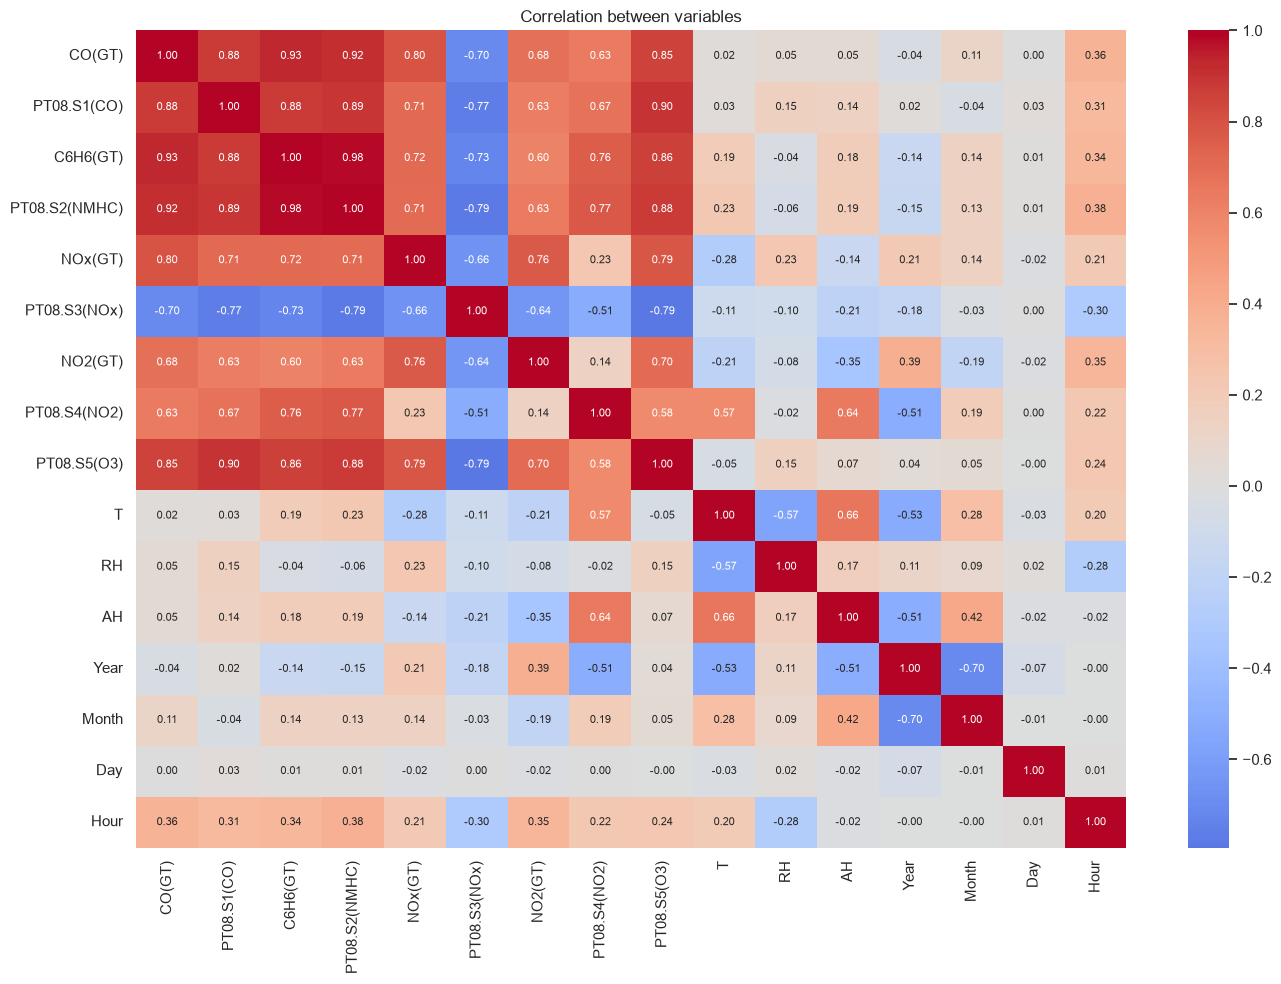

In [9]:
# Correlation matrix
plt.figure(figsize=(14, 10))
sns.heatmap(df.corr(), annot=True, fmt=".2f", annot_kws={"size": 8}, cmap="coolwarm", center=0)
plt.title("Correlation between variables")
plt.tight_layout()
plt.show()

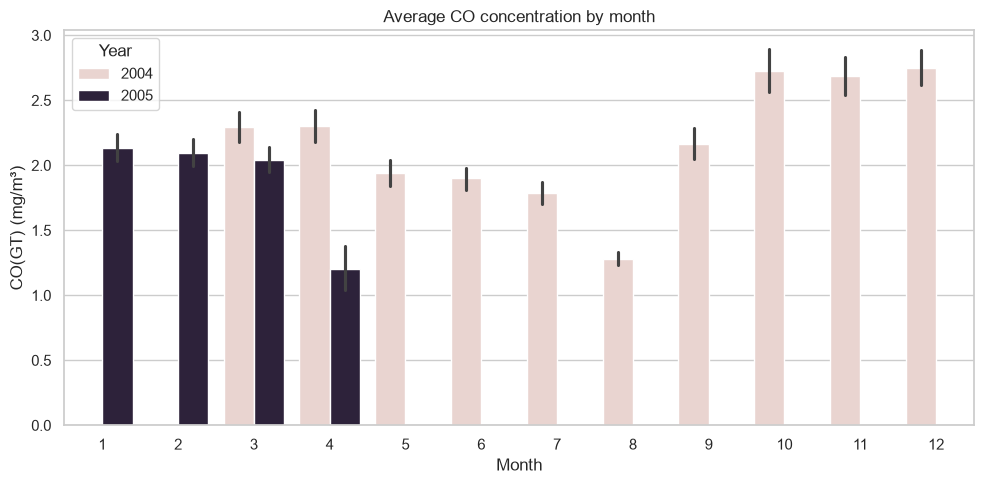

In [10]:
# CO concentration by month and year
plt.figure(figsize=(10, 5))
sns.barplot(data=df, x="Month", y=TARGET, hue="Year")
plt.title("Average CO concentration by month")
plt.xlabel("Month")
plt.ylabel(f"{TARGET} (mg/m³)")
plt.tight_layout()
plt.show()

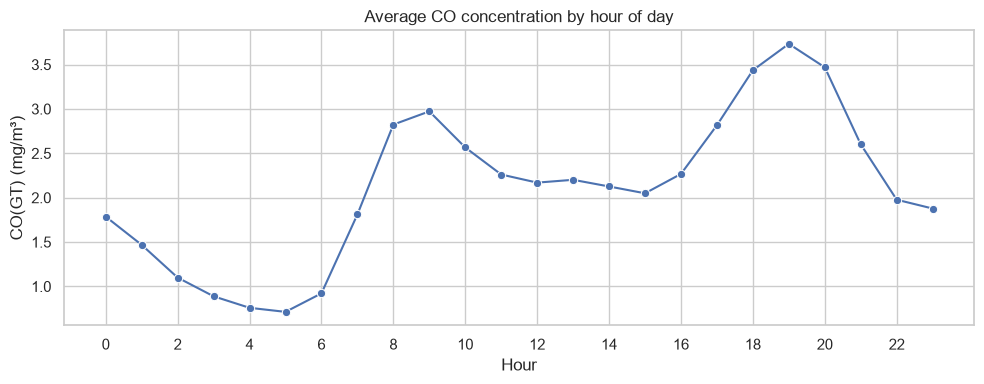

In [11]:
# CO concentration by hour of day
plt.figure(figsize=(10, 4))
sns.lineplot(data=df, x="Hour", y=TARGET, estimator="mean", errorbar=None, marker="o")
plt.title("Average CO concentration by hour of day")
plt.xlabel("Hour")
plt.ylabel(f"{TARGET} (mg/m³)")
plt.xticks(range(0, 24, 2))
plt.tight_layout()
plt.show()

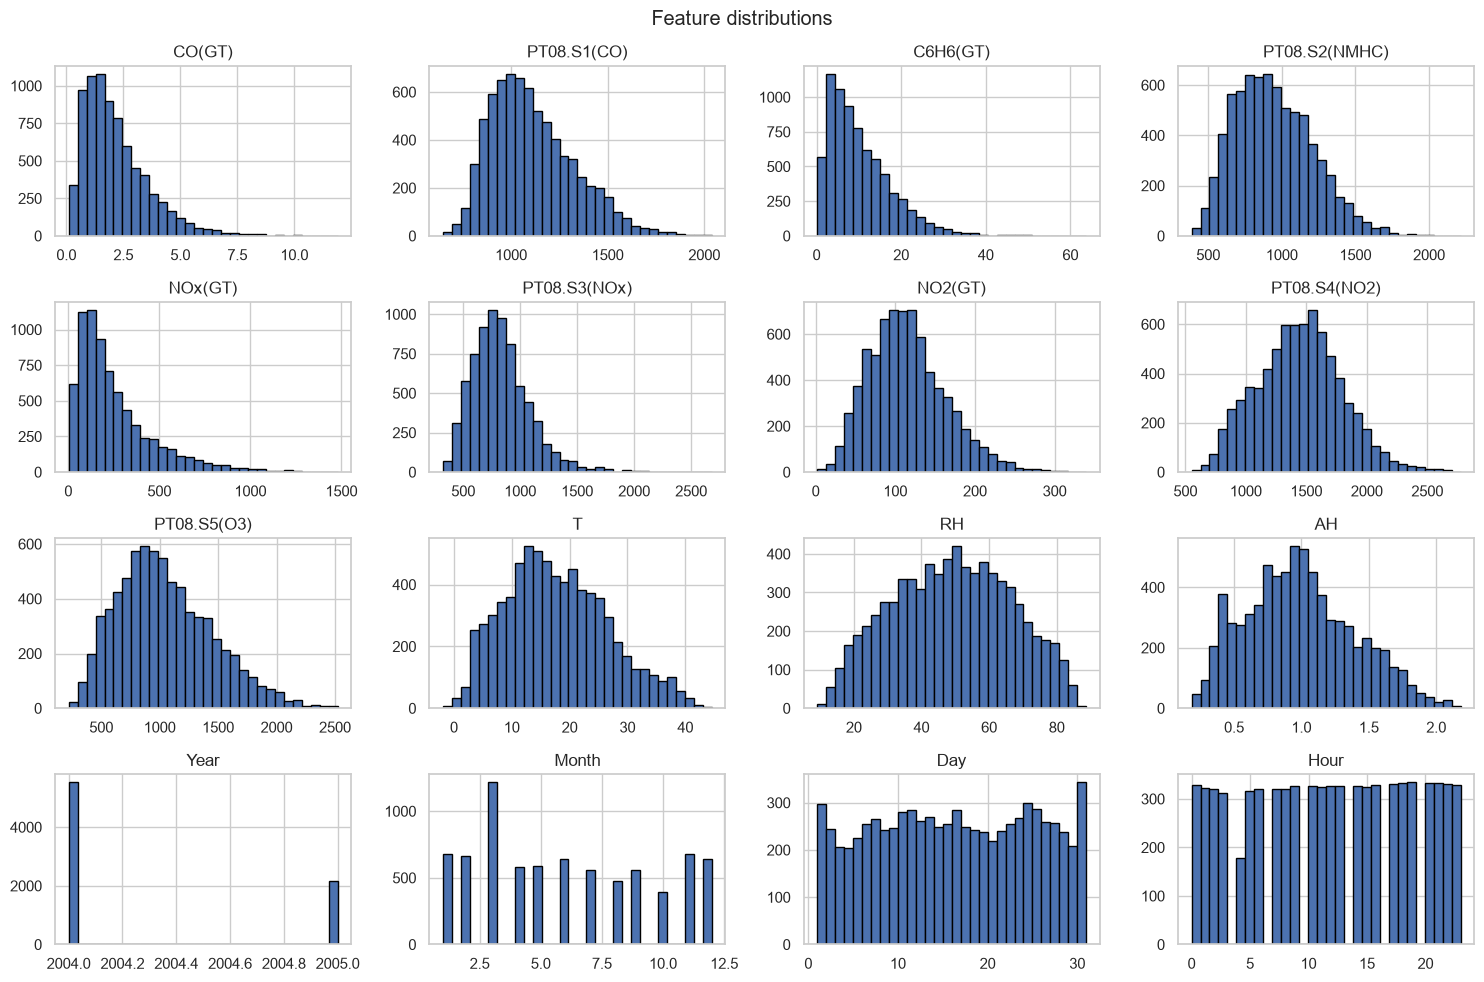

In [12]:
# Feature distributions
axes = df.hist(figsize=(15, 10), bins=30, edgecolor="black")
plt.suptitle("Feature distributions")
plt.tight_layout()
plt.show()

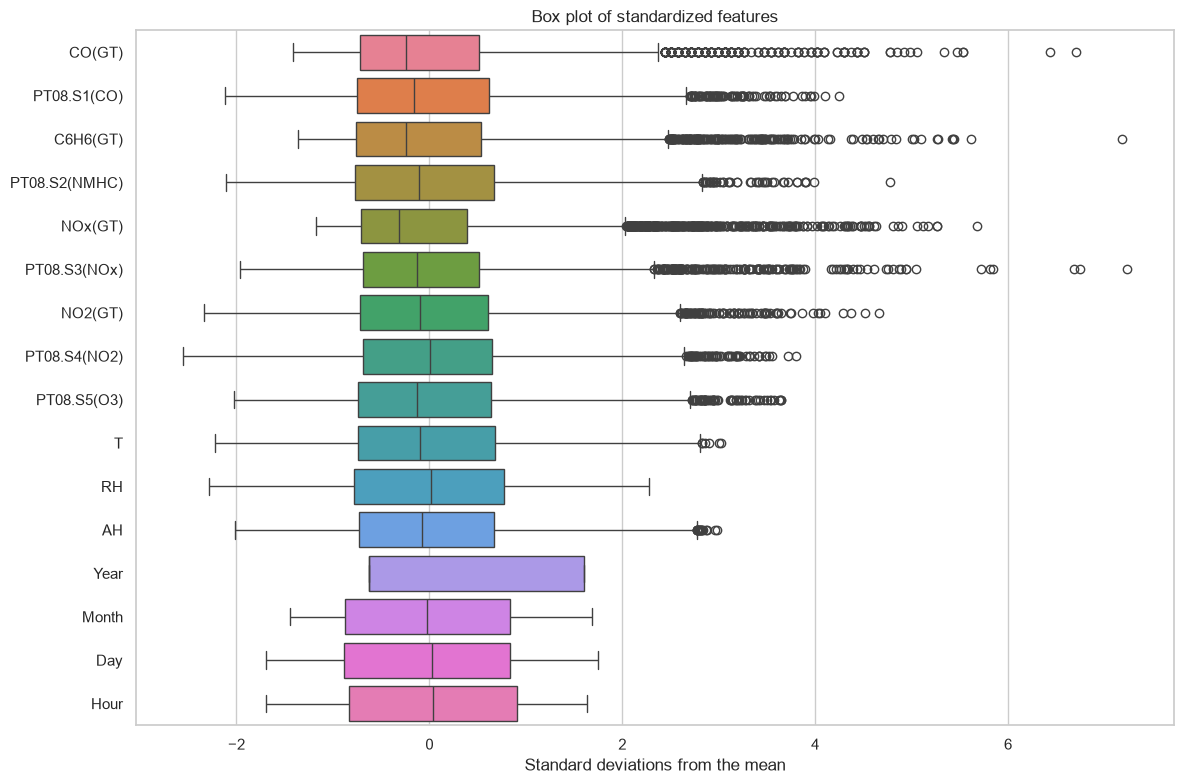

In [13]:
# Box plots on standardized values, so features with very different scales are comparable
df_std = (df - df.mean()) / df.std()

plt.figure(figsize=(12, 8))
sns.boxplot(data=df_std, orient="h")
plt.title("Box plot of standardized features")
plt.xlabel("Standard deviations from the mean")
plt.tight_layout()
plt.show()

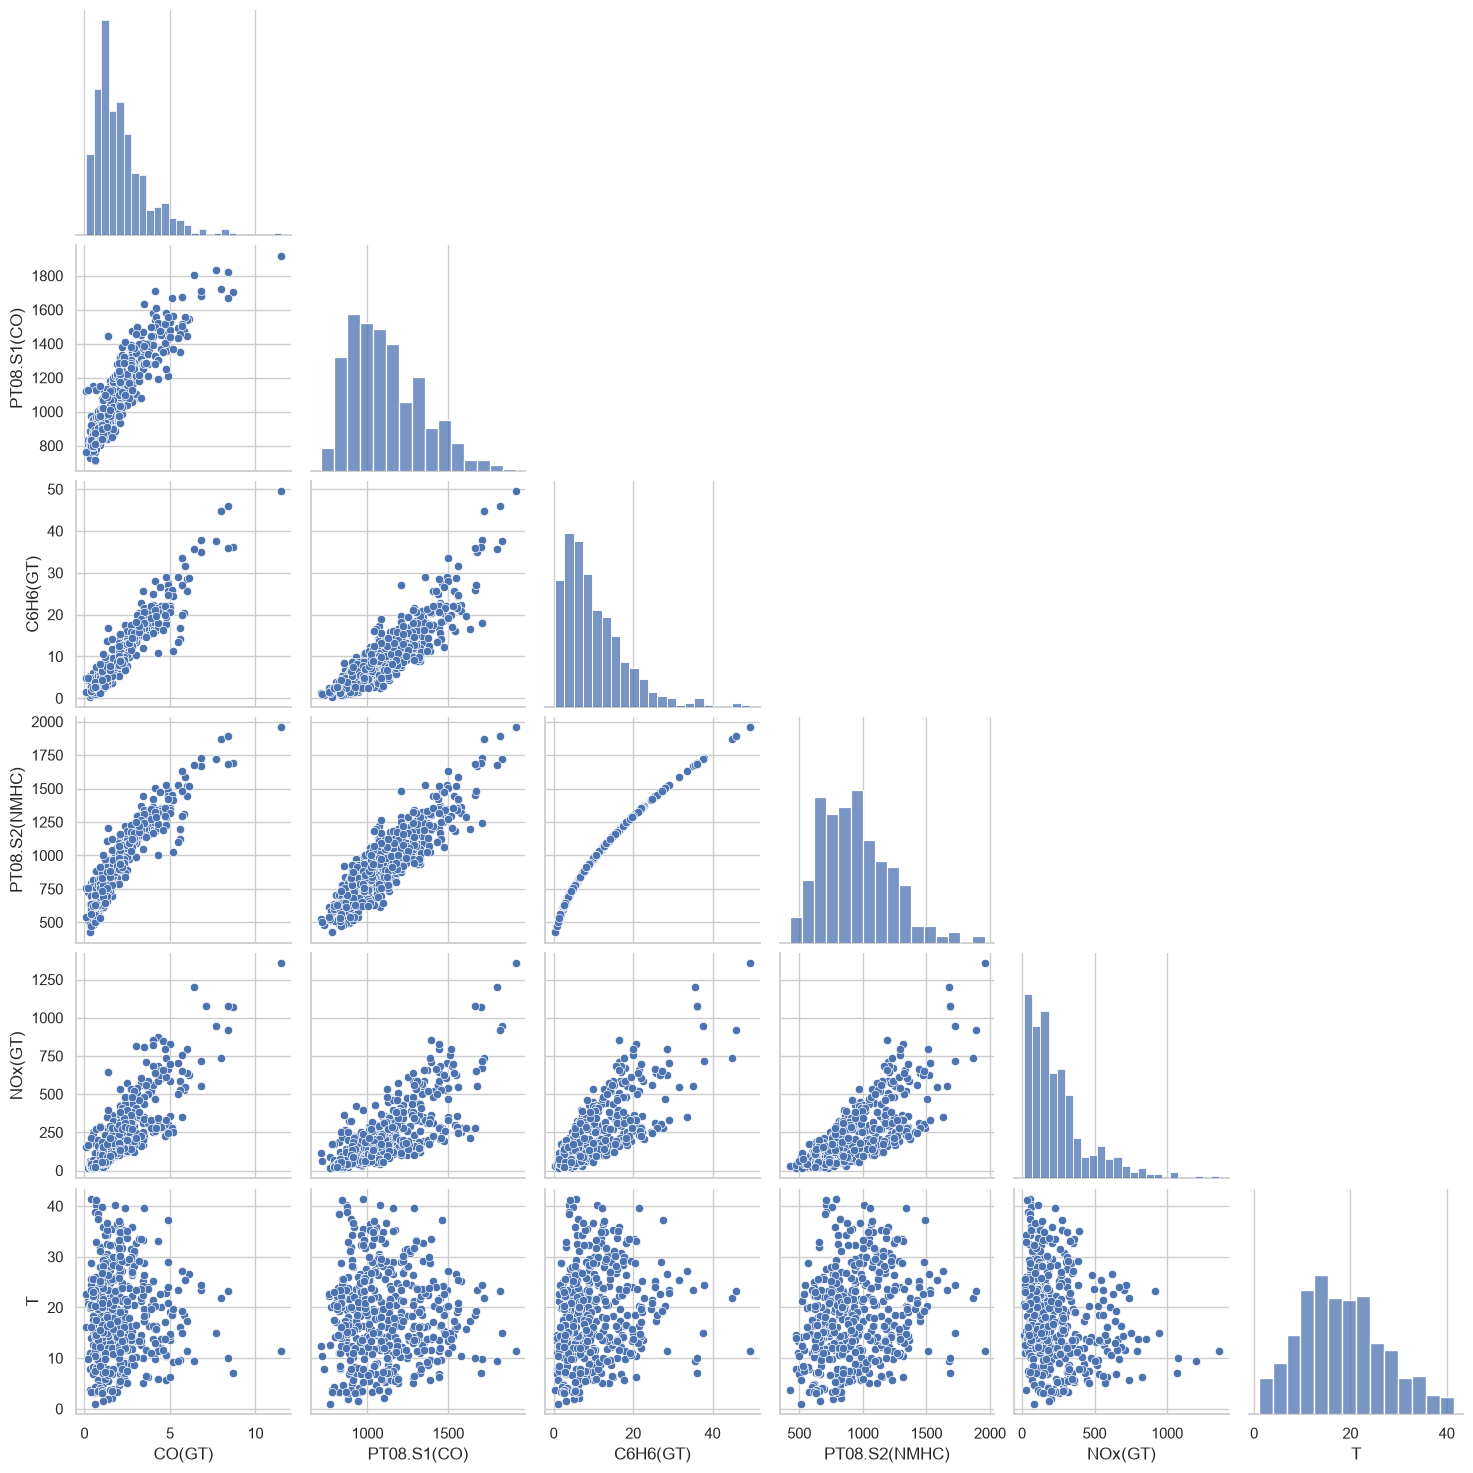

In [14]:
# Pair plot on a sample and the most relevant columns (a full pair plot is very slow)
pair_cols = [TARGET, "PT08.S1(CO)", "C6H6(GT)", "PT08.S2(NMHC)", "NOx(GT)", "T"]
sns.pairplot(df[pair_cols].sample(500, random_state=RANDOM_STATE), corner=True)
plt.show()

## 5. Train/test split

The data is split **before** any scaling or imputation, and the target is left in its original units (mg/m³) so the error metrics are directly interpretable. Imputation and scaling are fitted on the training set only, as part of each model's pipeline.

In [15]:
X = df.drop(columns=TARGET)
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE
)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")

Train: (6139, 15), Test: (1535, 15)


## 6. Model training and comparison

Each model is wrapped in a pipeline (median imputation → standard scaling → regressor). Every model is trained once and evaluated on the same test set.

In [16]:
regressors = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
    "Support Vector Machine": SVR(),
    "K-Nearest Neighbors": KNeighborsRegressor(),
    "Neural Network": MLPRegressor(max_iter=1000, random_state=RANDOM_STATE),
}
if XGBRegressor is not None:
    regressors["XGBoost"] = XGBRegressor(random_state=RANDOM_STATE)

models = {
    name: make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), reg)
    for name, reg in regressors.items()
}

In [17]:
def evaluate(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(y_true, y_pred),
    }

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    results.append({"Model": name, **evaluate(y_test, model.predict(X_test))})

results_df = (
    pd.DataFrame(results)
    .sort_values("R2", ascending=False)
    .reset_index(drop=True)
)
results_df.round(4)

,Model,MAE,MSE,RMSE,R2
0,XGBoost,0.1957,0.0834,0.2887,0.9600
1,Neural Network,0.2294,0.1168,0.3418,0.9439
2,Random Forest,0.2248,0.1250,0.3535,0.9400
3,Support Vector Machine,0.2175,0.1346,0.3668,0.9354
4,K-Nearest Neighbors,0.2466,0.1410,0.3755,0.9323
5,Linear Regression,0.3047,0.2206,0.4697,0.8941
6,Decision Tree,0.3367,0.2825,0.5315,0.8644


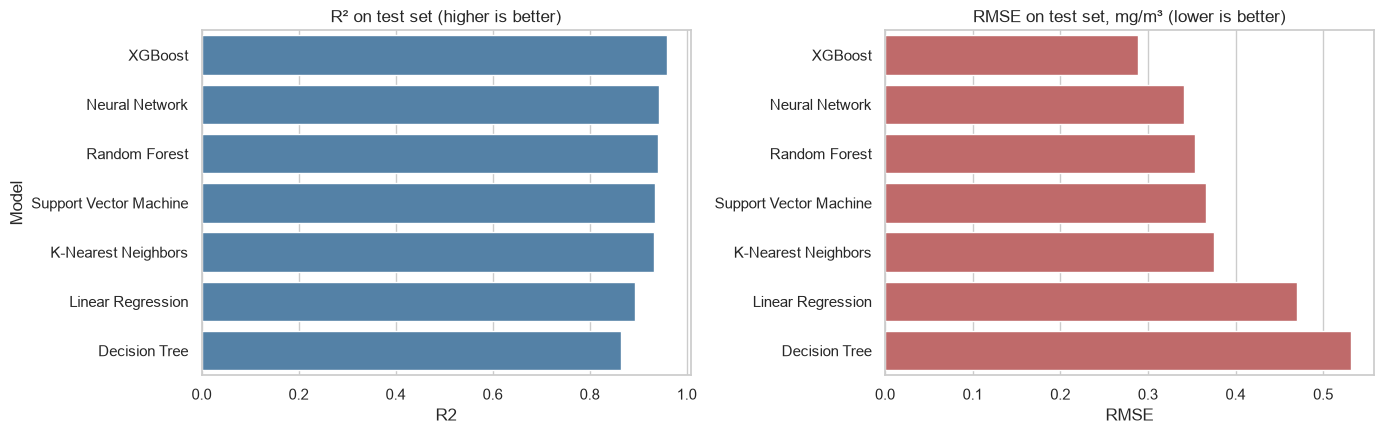

In [18]:
# Visual comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.barplot(data=results_df, y="Model", x="R2", ax=axes[0], color="steelblue")
axes[0].set_title("R² on test set (higher is better)")

sns.barplot(data=results_df, y="Model", x="RMSE", ax=axes[1], color="indianred")
axes[1].set_title("RMSE on test set, mg/m³ (lower is better)")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

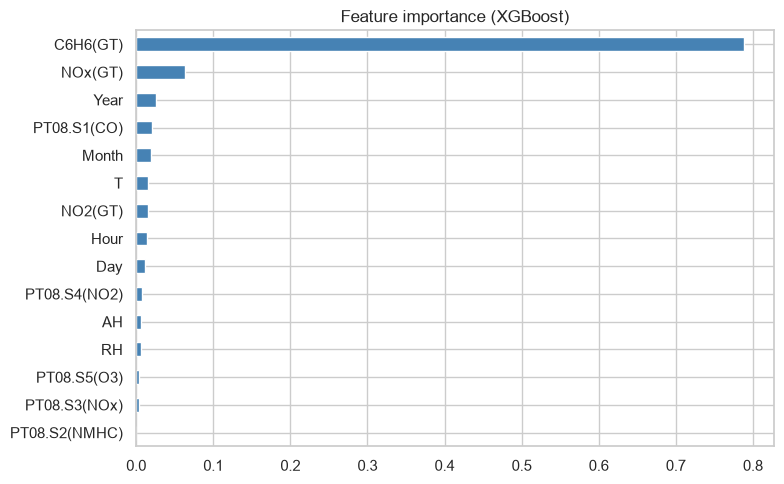

In [19]:
# Which features drive the best tree-based model?
tree_models = [n for n in results_df["Model"] if n in ("Random Forest", "XGBoost", "Decision Tree")]
best_tree = tree_models[0]
pipe = models[best_tree]

importances = pd.Series(
    pipe[-1].feature_importances_, index=X_train.columns
).sort_values()

importances.plot.barh(figsize=(8, 5), color="steelblue")
plt.title(f"Feature importance ({best_tree})")
plt.tight_layout()
plt.show()

## 7. Conclusions

- The `-200` placeholders must be treated as missing values; otherwise they are read as genuine measurements.
- Compare the models using the table and charts above. Tree ensembles (Random Forest, XGBoost) and K-Nearest Neighbors typically do best on this dataset, while Linear Regression is the weakest because the sensor responses are non-linear.
- The split is random, so neighbouring hours can appear in both train and test sets, which makes the scores somewhat optimistic. For a stricter estimate, split chronologically (train on earlier months, test on the latest ones).
- Possible next steps: hyper-parameter tuning (`GridSearchCV` / `RandomizedSearchCV`), cross-validation, and lag features (CO a few hours earlier).